# 04 · CPU 极简训练：loss、验证与 checkpoint

**Source audit:** [karpathy/nanoGPT](https://github.com/karpathy/nanoGPT/tree/3adf61e154c3fe3fca428ad6bc3818b27a3b8291) at `3adf61e154c3`; relevant files: `model.py`, `train.py`, `sample.py`, `data/shakespeare_char/prepare.py`, `config/train_shakespeare_char.py`.

**Scope:** The notebook uses a small **educational adaptation** (`nanogpt_edu.py`) consistent with the original architecture, not a verbatim copy of the full upstream training program. No pretrained weights, external datasets, downloads, distributed GPUs, or performance reproduction are claimed. Figures and prints are generated by real local CPU executions. The project's README has marked nanoGPT deprecated since Nov 2025 and points to nanochat.

## 最小可运行训练闭环

参考 `train.py`：批次抽样 → 前向 → CE Loss → 反向 → 梯度裁剪 → AdamW 更新 → 定期验证。这里训练**小得多**的模型，用原创重复语料展示过拟合/收敛趋势；不复现 GPT-2 的指标、速度或数据规模。

In [1]:
from pathlib import Path
import sys, torch, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
# Compatible with starting Jupyter from the notebook directory OR repository root.
P = Path.cwd().resolve()
ROOT = P if (P / 'nanogpt_edu.py').exists() else P.parent
if not (ROOT / 'nanogpt_edu.py').exists():
    raise RuntimeError('Open this notebook from tutorials/nanogpt/notebooks or the tutorials/nanogpt directory')
sys.path.insert(0, str(ROOT))
from nanogpt_edu import GPTConfig, GPT, char_dataset, get_batch, training_text, lr_schedule, parameter_groups
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(min(2, torch.get_num_threads()))
torch.manual_seed(42); np.random.seed(42)
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| CPU tutorial', '| path:', ROOT)

Python: 3.13.5 | PyTorch: 2.10.0+cpu | CPU tutorial | path: /mnt/notebook-builder/tutorials/nanogpt


In [2]:
from dataclasses import asdict
all_ids,stoi,itos=char_dataset(training_text(repeats=25))
cut=int(len(all_ids)*0.90)
train_ids,val_ids=all_ids[:cut],all_ids[cut:]
cfg=GPTConfig(vocab_size=len(stoi),block_size=24,n_layer=1,n_head=2,n_embd=32)
model=GPT(cfg);opt=torch.optim.AdamW(parameter_groups(model,0.02),lr=3e-3)
print('Train tokens:',len(train_ids),'Validation tokens:',len(val_ids),'Vocab:',len(stoi))
print('Model parameter count:',sum(p.numel() for p in model.parameters()))
assert len(val_ids)>cfg.block_size

Train tokens: 4657 Validation tokens: 518 Vocab: 27
Model parameter count: 14400


step 01/50 train_loss=3.317 val_loss=3.240
step 10/50 train_loss=2.869 val_loss=2.861
step 20/50 train_loss=2.627 val_loss=2.642
step 30/50 train_loss=2.520 val_loss=2.466
step 40/50 train_loss=2.353 val_loss=2.257
step 50/50 train_loss=2.203 val_loss=2.212


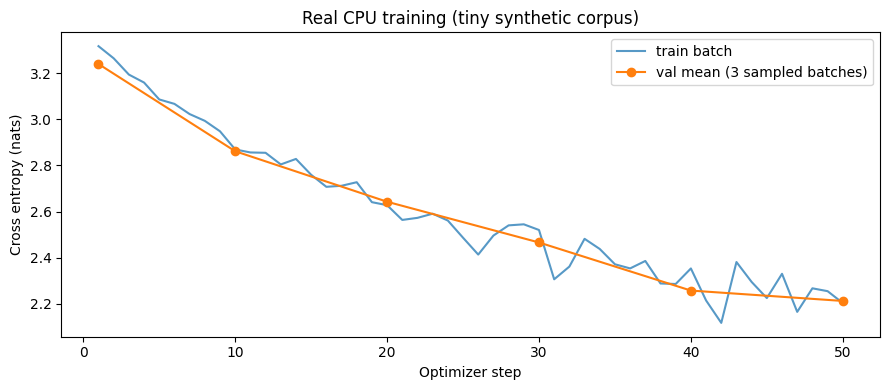

In [3]:
train_history=[];val_history=[];val_steps=[]
steps=50
for step in range(steps):
    model.train()
    x,y=get_batch(train_ids,cfg.block_size,8)
    opt.zero_grad(set_to_none=True)
    _,loss=model(x,y)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
    opt.step()
    train_history.append(float(loss.item()))
    if step==0 or (step+1)%10==0:
        model.eval()
        with torch.no_grad():
            vloss=np.mean([model(*get_batch(val_ids,cfg.block_size,8))[1].item() for _ in range(3)])
        val_steps.append(step+1);val_history.append(float(vloss))
        print(f'step {step+1:02d}/{steps} train_loss={loss.item():.3f} val_loss={vloss:.3f}')
assert len(train_history)==steps and np.isfinite(train_history).all()
fig,ax=plt.subplots(figsize=(9,4));ax.plot(range(1,steps+1),train_history,alpha=.75,label='train batch')
ax.plot(val_steps,val_history,'o-',label='val mean (3 sampled batches)')
ax.set_xlabel('Optimizer step');ax.set_ylabel('Cross entropy (nats)');ax.set_title('Real CPU training (tiny synthetic corpus)');ax.legend();fig.tight_layout()
fig.savefig(FIG/'04_training_loss.png',dpi=140);display(fig);plt.close(fig)

Saved checkpoint: /mnt/notebook-builder/tutorials/nanogpt/outputs/nanogpt_tiny_checkpoint.pt bytes: 65235
Final sampled validation loss: 2.212


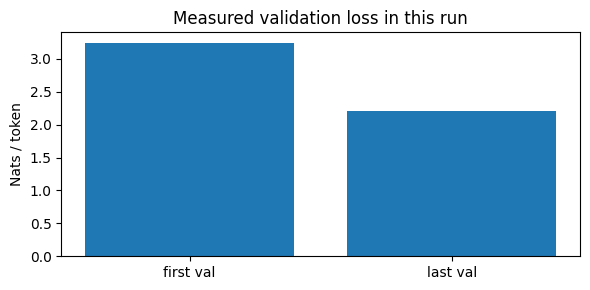

In [4]:
checkpoint={'config':asdict(cfg), 'model':model.state_dict(), 'stoi':stoi, 'itos':itos,
            'train_steps':steps, 'data_source':'original synthetic text in nanogpt_edu.py'}
path=OUT/'nanogpt_tiny_checkpoint.pt';torch.save(checkpoint,path)
print('Saved checkpoint:',path,'bytes:',path.stat().st_size)
print('Final sampled validation loss:',round(val_history[-1],3))
assert path.exists() and val_history[-1]<val_history[0]
fig,ax=plt.subplots(figsize=(6,3));ax.bar(['first val','last val'],[val_history[0],val_history[-1]])
ax.set_title('Measured validation loss in this run');ax.set_ylabel('Nats / token');fig.tight_layout()
fig.savefig(FIG/'04_val_comparison.png',dpi=130);display(fig);plt.close(fig)

### 误差和限制

小样本 validation 是估计值，且合成文本重复，无法外推到 Shakespeare/OpenWebText。`torch.save` 的 checkpoint 只应加载可信文件。练习：改变 `steps`、`dropout`、`weight_decay` 并检查验证损失是否稳定改善。